<a href="https://colab.research.google.com/github/UnnimayaVAshok/Data_Science/blob/main/Class_works/mask.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import numpy as np
import pandas as ps
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os
from skimage.io import imread
from skimage.transform import resize
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense

In [4]:
os.listdir('/content/drive/MyDrive/Maskdata')

['without_mask', 'with_mask']

In [5]:
len(os.listdir('/content/drive/MyDrive/Maskdata/with_mask'))

1432

In [6]:
len(os.listdir('/content/drive/MyDrive/Maskdata/without_mask'))

1718

In [7]:
os.listdir('/content/drive/MyDrive/Maskdatatest')

['with_mask', 'without_mask']

In [8]:
len(os.listdir('/content/drive/MyDrive/Maskdatatest/with_mask'))

60

In [9]:
len(os.listdir('/content/drive/MyDrive/Maskdatatest/without_mask'))

42

In [10]:
train_data = sorted(os.listdir('/content/drive/MyDrive/Maskdata'))
train_data

['with_mask', 'without_mask']

In [11]:
test_data = sorted(os.listdir('/content/drive/MyDrive/Maskdatatest'))
test_data

['with_mask', 'without_mask']

In [12]:
x_train = []
y_train = []
datadir = '/content/drive/MyDrive/Maskdata'

In [13]:
for i in train_data:
  path = os.path.join(datadir,i)
  for img in os.listdir(path):
    img_read = imread(os.path.join(path,img))
    img_res = resize(img_read,(150,150,3))
    x_train.append(img_res)
    y_train.append(train_data.index(i))

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [14]:
x_test = []
y_test = []
testdir = '/content/drive/MyDrive/Maskdatatest'

In [15]:
for i in test_data:
  path = os.path.join(testdir,i)
  for img in os.listdir(path):
    img_read = imread(os.path.join(path,img))
    img_res = resize(img_read,(150,150,3))
    x_test.append(img_res)
    y_test.append(test_data.index(i))

In [16]:
x_train = np.array(x_train)
y_train = np.array(y_train)
x_test = np.array(x_test)
y_test = np.array(y_test)

In [17]:
model = Sequential()
model.add(Conv2D(32,(3,3),input_shape=(150,150,3),activation='relu'))
model.add(MaxPool2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(50,activation='relu'))
model.add(Dense(2,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [19]:
model.fit(x_train,y_train,epochs=100,batch_size=200)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 407ms/step - accuracy: 0.5486 - loss: 2.6347
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.7063 - loss: 0.5686
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.8648 - loss: 0.3225
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9210 - loss: 0.2065
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.9457 - loss: 0.1531
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.9641 - loss: 0.1148
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.9733 - loss: 0.0925
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.9787 - loss: 0.0714
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - accuracy: 0.9873 - loss: 0.0503
Epoch 10/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.9914 - loss: 0.0382
Epoch 11/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9949 - loss: 0.0319
Epoch 12/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/st

In [20]:
model.evaluate(x_test,y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 682ms/step - accuracy: 0.9706 - loss: 0.2622


[0.2622097134590149, 0.970588207244873]

In [21]:
y_pred = model.predict(x_test[:20])
y_pred = np.argmax(y_pred,axis=1)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [22]:
y_test[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

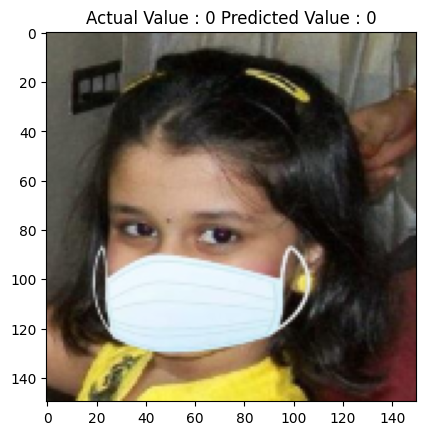

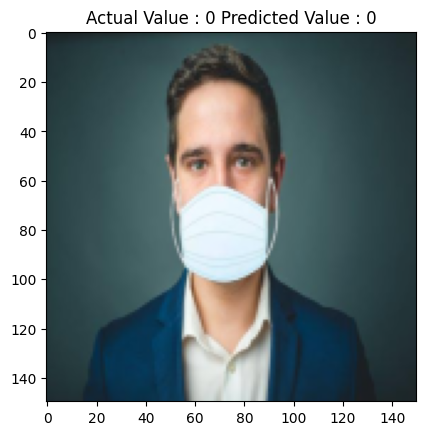

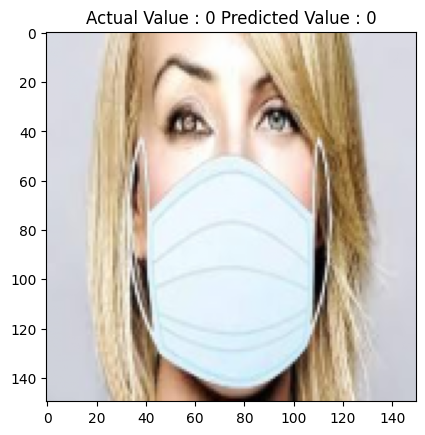

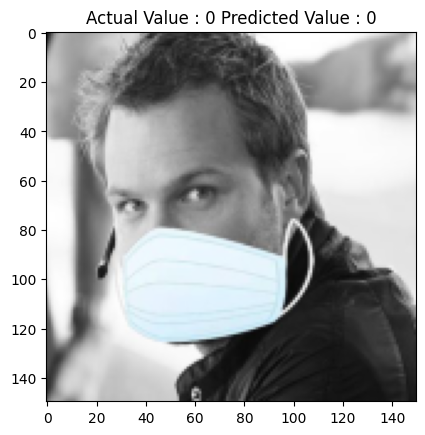

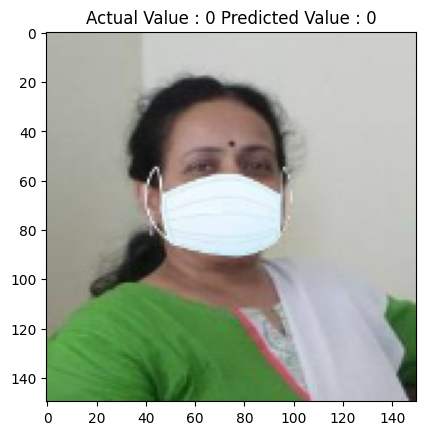

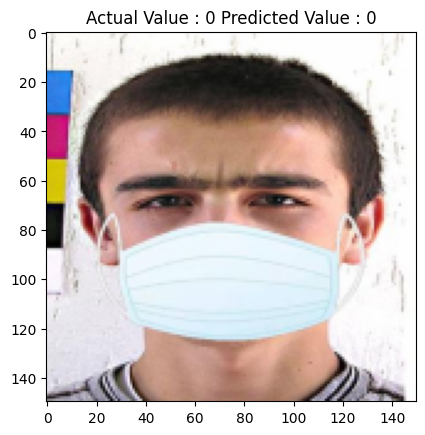

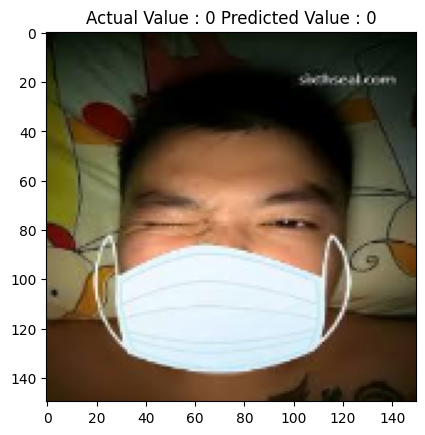

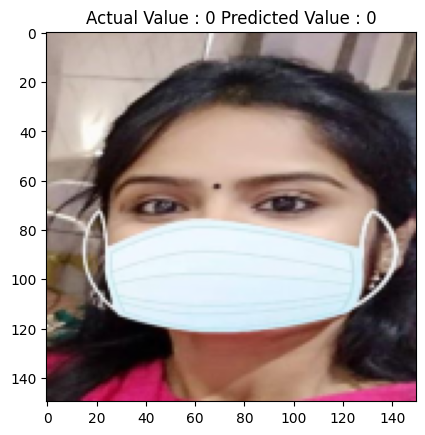

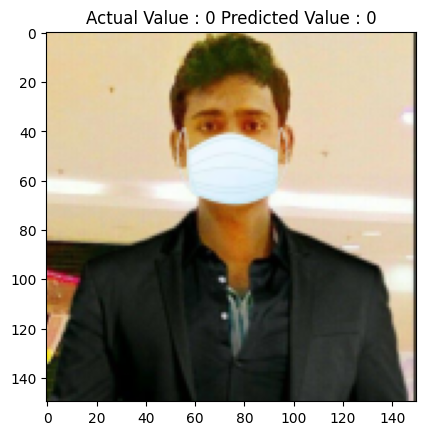

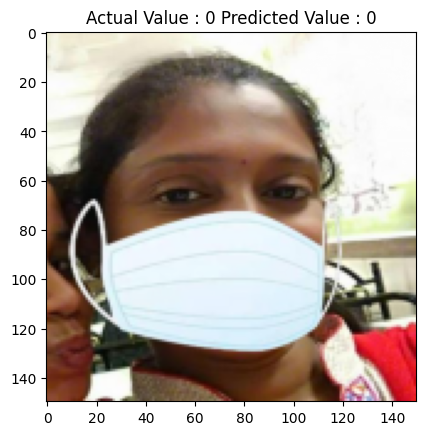

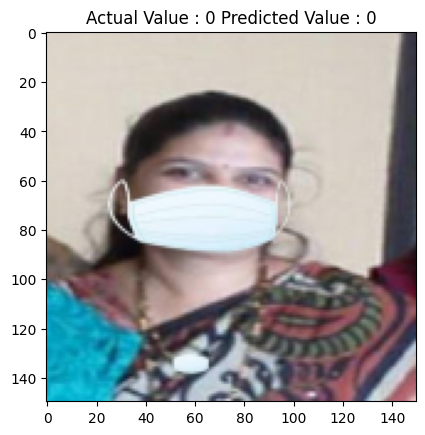

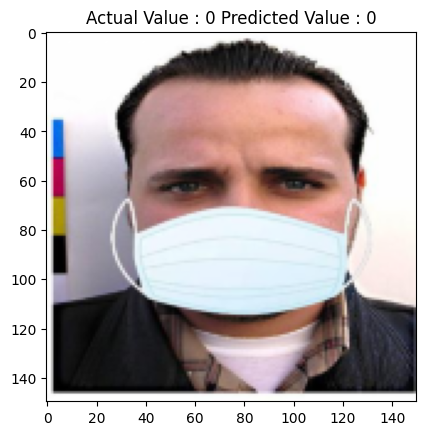

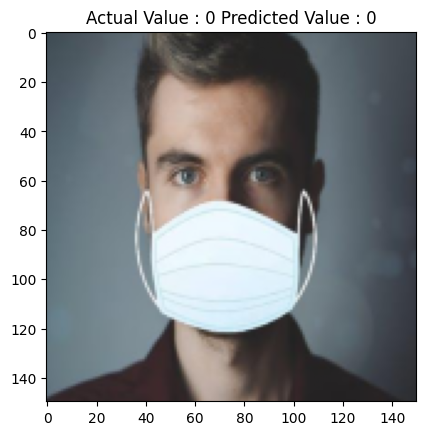

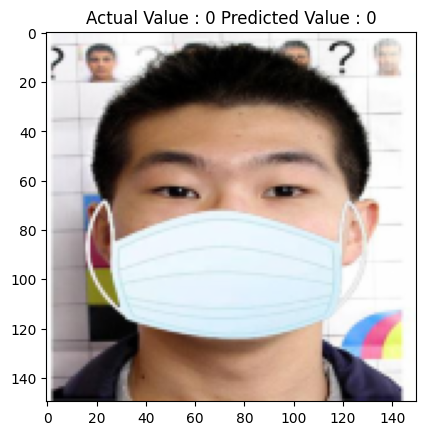

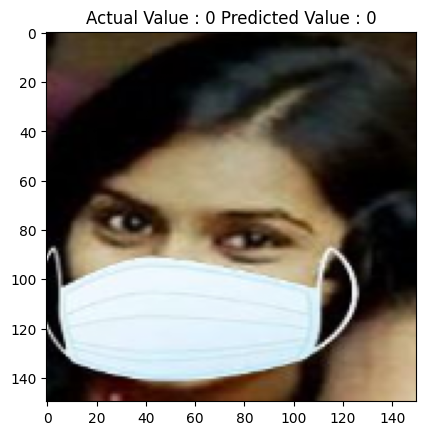

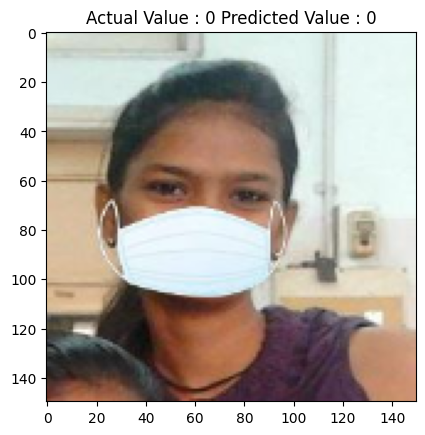

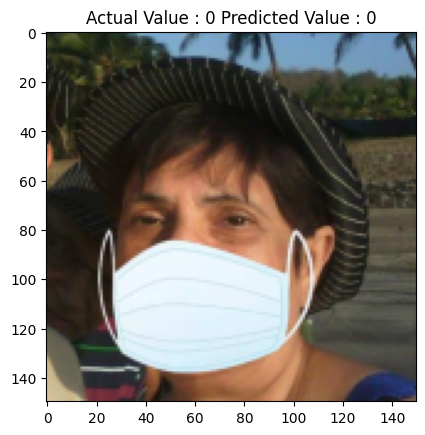

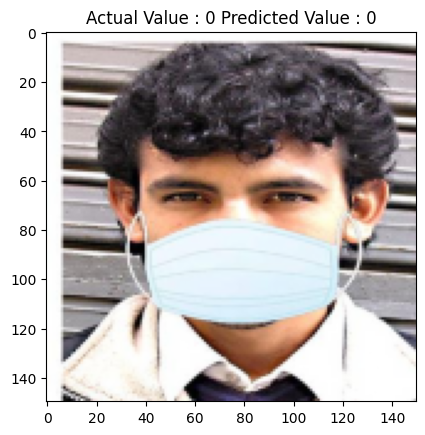

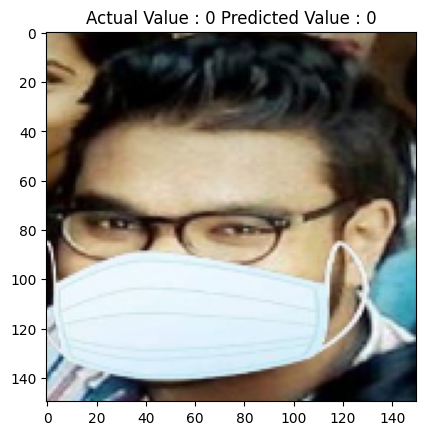

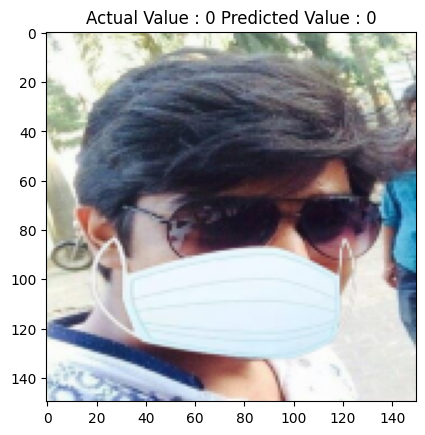

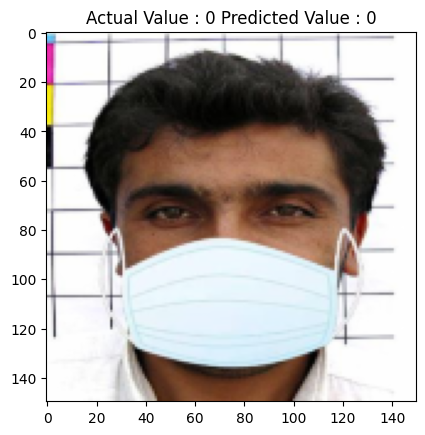

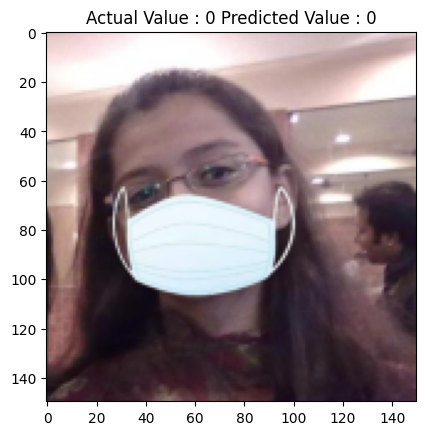

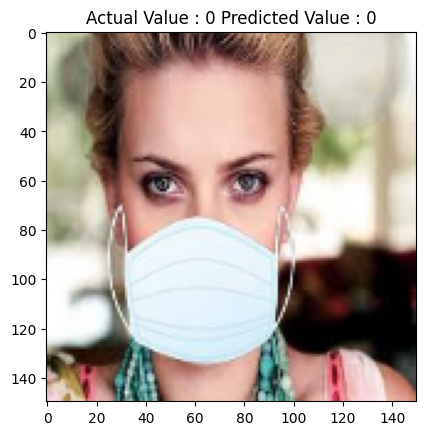

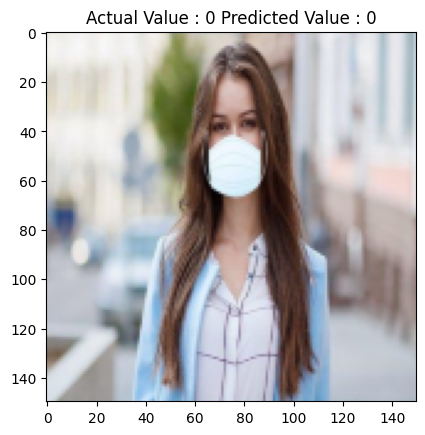

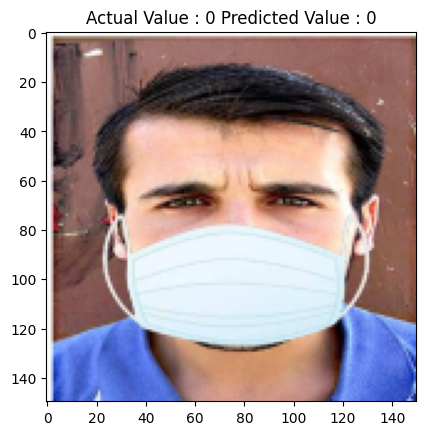

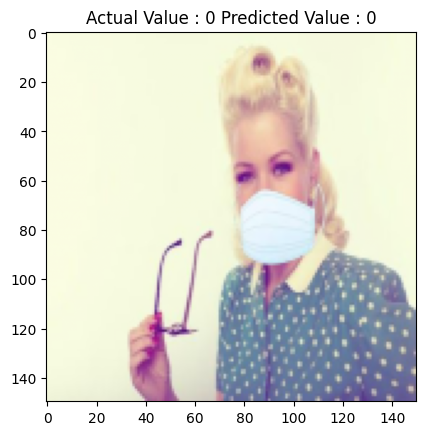

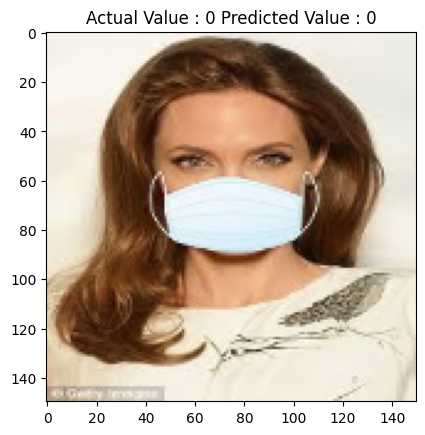

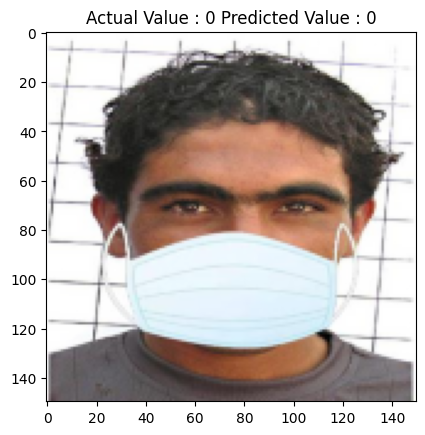

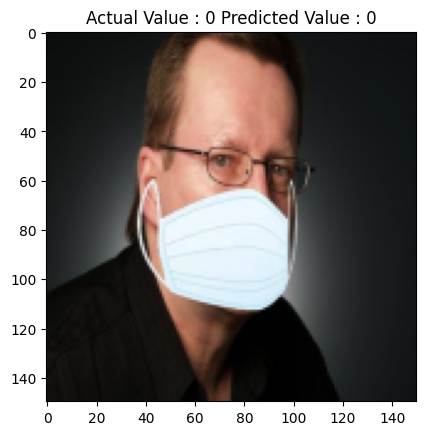

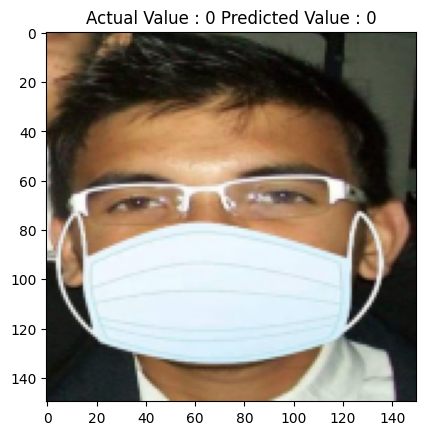

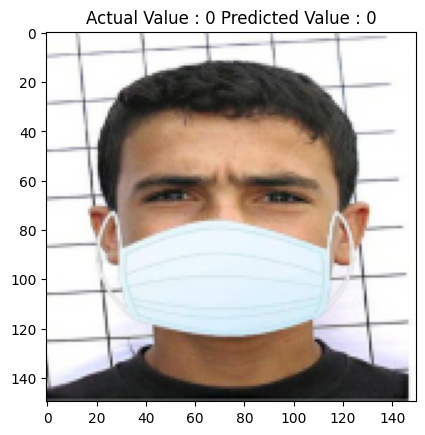

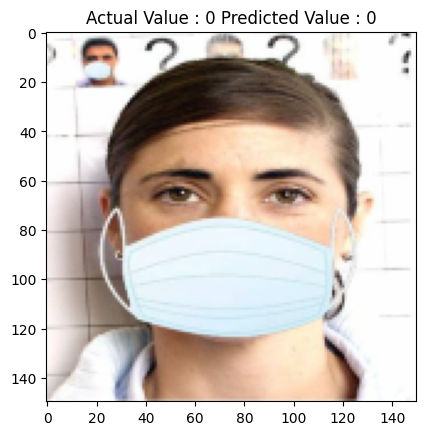

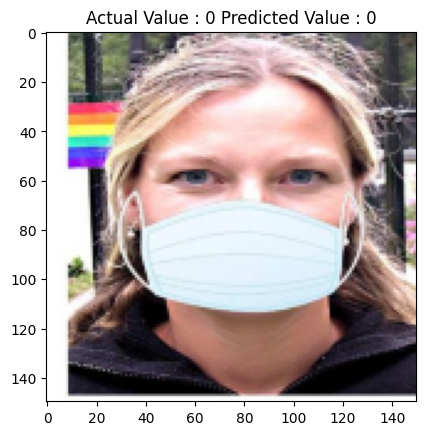

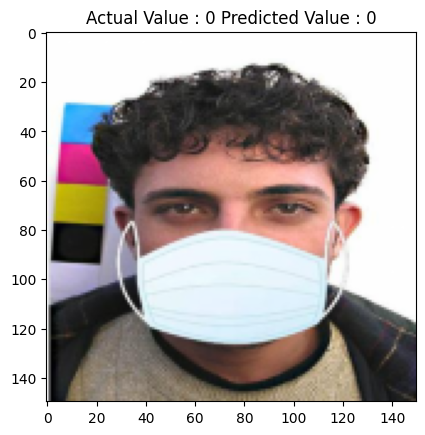

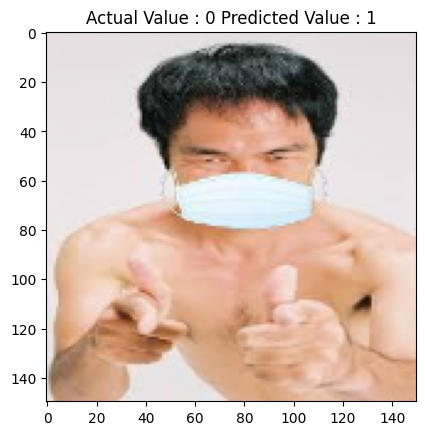

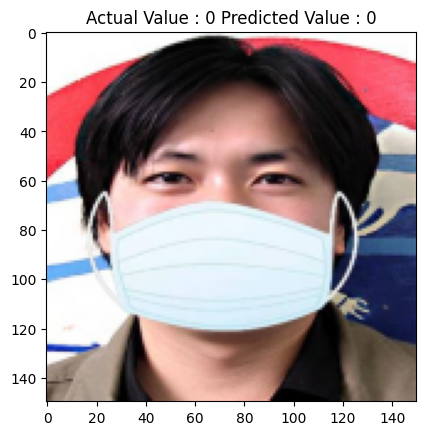

In [28]:
for i in range(20,56):
  y_pred = model.predict(x_test[i].reshape(1,150,150,3),verbose = 0)
  output = np.argmax(y_pred)
  plt.imshow(x_test[i])
  plt.title(f"Actual Value : {y_test[i]} Predicted Value : {output}")
  plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


Text(0.5, 1.0, 'With mask')

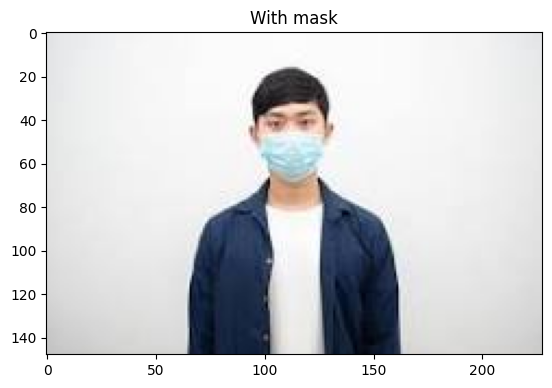

In [46]:
image = '/content/mask.jpg'
img_read = imread(image)
img_res = resize(img_read,(1,150,150,3))
y_pred = model.predict(img_res)
output = np.argmax(y_pred)
output

plt.imshow(img_read)
plt.title("With mask" if output == 0 else "Without mask")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


Text(0.5, 1.0, 'Without mask')

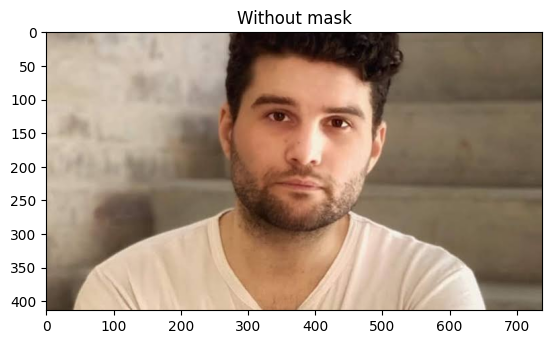

In [47]:
image = '/content/withoutmask.jpg'
img_read = imread(image)
img_res = resize(img_read,(1,150,150,3))
y_pred = model.predict(img_res)
output = np.argmax(y_pred)
output

plt.imshow(img_read)
plt.title("With mask" if output == 0 else "Without mask")